# Spam Message Classifier using NLP

**Internship Task 03 — IncodeVision Machine Learning Internship**

## Objective
Build a beginner-friendly machine learning model that classifies a text message as **spam** or **ham (not spam)**.

## What this notebook does
1. Load and inspect the dataset.
2. Check missing values and remove duplicate rows.
3. Explore the distribution of spam and ham messages.
4. Split the data into training and testing sets.
5. Convert text into numerical features using TF-IDF.
6. Train a Logistic Regression classifier.
7. Evaluate it using accuracy, precision, recall, F1-score, and a confusion matrix.
8. Test the model on a few new messages.

> **Dataset note:** The supplied file contains short, SMS-like messages in the `Message` column. This is suitable for learning spam text classification, but it is not clearly a full-email dataset. If the internship evaluator strictly requires email bodies, replace `mail_data.csv` with a properly sourced email dataset before submission.

## 1. Import the libraries

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

## 2. Load the dataset

In [2]:
df = pd.read_csv("mail_data.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (6567, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Inspect and clean the data

In [3]:
print("Column names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows before cleaning:", df.duplicated().sum())
print("\nLabel counts before cleaning:")
print(df["Category"].value_counts())

Column names: ['Category', 'Message']

Missing values per column:
Category    0
Message     0
dtype: int64

Duplicate rows before cleaning: 1407

Label counts before cleaning:
Category
ham     4825
spam    1742
Name: count, dtype: int64


In [4]:
# Keep only the columns needed for this project and remove rows with missing data.
df = df[["Category", "Message"]].dropna().copy()

# Standardize label and message formatting.
df["Category"] = df["Category"].astype(str).str.strip().str.lower()
df["Message"] = df["Message"].astype(str).str.strip()

# Keep only the two expected labels and non-empty messages.
df = df[df["Category"].isin(["ham", "spam"])]
df = df[df["Message"] != ""]

# Exact duplicate rows do not add new information, so remove them.
df = df.drop_duplicates().reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("\nLabel counts after cleaning:")
print(df["Category"].value_counts())

Cleaned dataset shape: (5160, 2)
Duplicate rows after cleaning: 0

Label counts after cleaning:
Category
ham     4516
spam     644
Name: count, dtype: int64


## 4. Visualize the label distribution

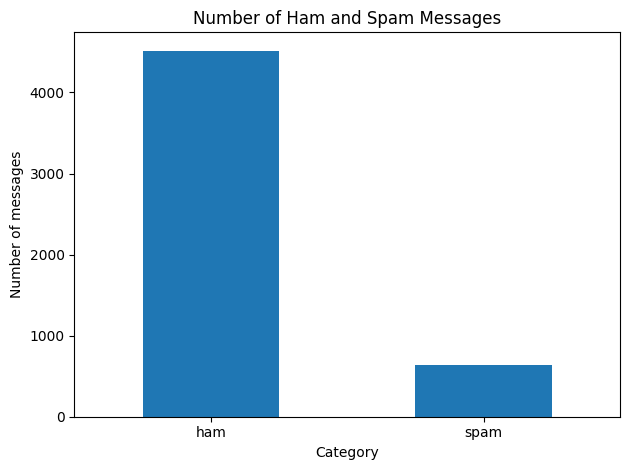

In [5]:
label_counts = df["Category"].value_counts().reindex(["ham", "spam"])
label_counts.plot(kind="bar", rot=0)
plt.title("Number of Ham and Spam Messages")
plt.xlabel("Category")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()

## 5. Prepare the input text and target labels

In [6]:
X = df["Message"]
y = df["Category"]

print("Total messages:", len(X))
print("\nClass proportions:")
print(y.value_counts(normalize=True).round(3))

Total messages: 5160

Class proportions:
Category
ham     0.875
spam    0.125
Name: proportion, dtype: float64


## 6. Split into training and testing data

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4128
Testing messages: 1032


## 7. Build and train the model with TF-IDF

In [8]:
# TF-IDF converts text into numerical features. The pipeline ensures that
# the vectorizer is fitted only on training messages.
model = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## 8. Evaluate the model

In [9]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
spam_precision = precision_score(y_test, y_pred, pos_label="spam", zero_division=0)
spam_recall = recall_score(y_test, y_pred, pos_label="spam", zero_division=0)
spam_f1 = f1_score(y_test, y_pred, pos_label="spam", zero_division=0)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Spam precision:    {spam_precision:.4f}")
print(f"Spam recall:       {spam_recall:.4f}")
print(f"Spam F1-score:     {spam_f1:.4f}")

Accuracy:          0.9661
Spam precision:    0.9796
Spam recall:       0.7442
Spam F1-score:     0.8458


In [10]:
print(classification_report(y_test, y_pred, labels=["ham", "spam"], zero_division=0))

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.98      0.74      0.85       129

    accuracy                           0.97      1032
   macro avg       0.97      0.87      0.91      1032
weighted avg       0.97      0.97      0.96      1032



## 9. Confusion matrix

Confusion matrix (rows = actual, columns = predicted):
[[901   2]
 [ 33  96]]


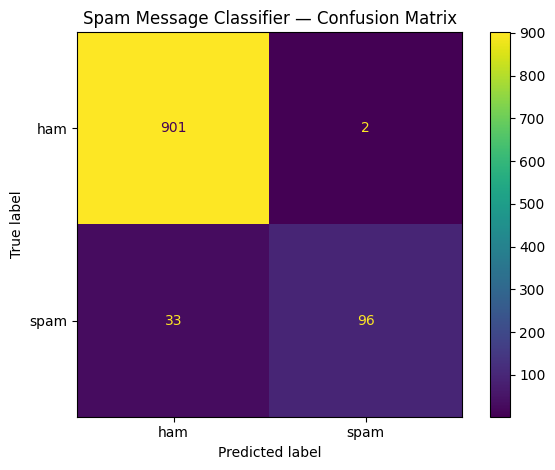

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["ham", "spam"],
).plot(values_format="d")
plt.title("Spam Message Classifier — Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. Try the model on new messages

In [12]:
new_messages = [
    "Congratulations! You have won a free prize. Click the link to claim it.",
    "Hi, are we still meeting at 5 pm today?",
    "URGENT! Claim your cash reward now. Terms apply.",
]

predictions = model.predict(new_messages)

for message, prediction in zip(new_messages, predictions):
    readable_label = "SPAM" if prediction == "spam" else "HAM (not spam)"
    print(f"Message: {message}\nPrediction: {readable_label}\n")

Message: Congratulations! You have won a free prize. Click the link to claim it.
Prediction: SPAM

Message: Hi, are we still meeting at 5 pm today?
Prediction: HAM (not spam)

Message: URGENT! Claim your cash reward now. Terms apply.
Prediction: SPAM



## 11. Conclusion

This project demonstrates a basic NLP classification workflow using TF-IDF and Logistic Regression. The test-set metrics above show how the model performed on held-out messages. Results may vary if the dataset changes.

### Limitations and possible improvements
- The supplied data contains SMS-like text, not clearly full email messages.
- The model may not recognize every new type of spam.
- Next steps could include comparing Multinomial Naive Bayes with Logistic Regression and testing on a separately sourced email dataset.